# 出生—死亡数据的空间自相关与空间回归

用 Schich 等人（2014）随文发布的出生—死亡数据库，问一个空间问题：
**文化名人的"净吸纳"在地理上有没有结构？如果有，它能不能被"出生规模"解释干净？**

方法与工具全部来自空间计量经济学的标准库 **PySAL**：
`libpysal`（空间权重）、`esda`（探索性空间数据分析）、`spreg`（空间回归）。
流程是五步：空间单元 → 权重 → 全局自相关 → 局部自相关 → 回归诊断与空间模型。

推荐：一次性装好你整套空间自相关工具（libpysal + esda + geopandas + splot）

In [1]:
import sys
sys.path.insert(0, r"C:\Users\Administrator\.workbuddy\binaries\python\pysal_pkgs")   # PySAL 装在隔离目录，未改动系统环境
import numpy as np
import pandas as pd
import libpysal, esda, spreg
from libpysal.weights import KNN, W
from esda.moran import Moran, Moran_Local
from spreg import OLS, ML_Lag, ML_Error
from pyproj import Transformer
from sklearn.neighbors import BallTree

print("libpysal", libpysal.__version__, "| esda", esda.__version__,
      "| spreg", spreg.__version__)

libpysal 4.15.0 | esda 2.10.0 | spreg 1.9.1


## 1　数据与空间单元

原始表是 17,828 个"出生地—死亡地"配对的地点，每个地点有经纬度与出生数 B、死亡数 D。

空间分析先要定义"单元"。这里用 **0.5° 经纬格网**：把地点汇总到格子，取
净吸纳度 z = (D − B)/√(B+D)。这个量的含义是"进来的人比出去的人多多少"，
用 √(B+D) 作分母，避免小格子因基数太小而数值爆炸。

In [2]:
NODES = pd.read_csv("fig1e_nodes.csv")
NODES = NODES[NODES.shown].copy()          # 剔除不绘制的离岸水体点

G = NODES.copy()
G["gy"] = np.floor(G.lat / 0.5) * 0.5 + 0.25     # 格心纬度
G["gx"] = np.floor(G.lon / 0.5) * 0.5 + 0.25     # 格心经度
G = (G.groupby(["gy", "gx"])
       .agg(B=("B", "sum"), D=("D", "sum"), nloc=("B", "size"))
       .reset_index())
G["tot"] = G.B + G.D
G["z"] = (G.D - G.B) / np.sqrt(G.tot)
print(f"地点 {len(NODES):,} → 格网单元 {len(G):,}；"
      f"出生 {G.B.sum():,.0f}、死亡 {G.D.sum():,.0f} 人次")
G[["B", "D", "tot", "z"]].describe().round(2)

地点 17,828 → 格网单元 2,670；出生 66,461、死亡 60,946 人次


,B,D,tot,z
count,2670.00,2670.00,2670.00,2670.00
mean,24.89,22.83,47.72,-1.02
std,100.06,143.21,239.67,2.01
min,0.00,0.00,1.00,-10.89
25%,2.00,0.00,2.00,-2.00
50%,5.00,2.00,7.00,-1.00
75%,15.00,7.00,22.00,-0.22
max,3114.00,4329.00,7443.00,26.62


## 2　空间权重

权重回答"谁是谁的邻居"。这里用 **k 近邻**（k=8，即周围一圈八个格子），并做**行标准化**
（每行权重和为 1，于是"空间滞后"就是邻居的简单平均）。

两个容易被忽略的细节：

**投影。** `KNN.from_array` 算的是欧氏距离。经纬度不是平面坐标，直接在度上算会高估
东西向距离，纬度越高偏得越多。所以先投影到 ETRS89 / LAEA Europe（EPSG:3035，单位米），
再取最近邻。下面的对照显示：投影与否，约 9% 的邻居会换人。

**行标准化要显式做。** libpysal 的 `KNN` 构造出的 `transform` 标记并不等于矩阵已经变换过
（此时行和是 k=8）。不显式设 `transform="r"`，`spreg` 会把 ρ 解释成"八个邻居之和"的系数，
数值会缩小 k 倍。行和自检是必要的一步。

In [3]:
ll = G[["gy", "gx"]].values                                  # (lat, lon)
tr = Transformer.from_crs(4326, 3035, always_xy=True)
mx, my = tr.transform(ll[:, 1], ll[:, 0])
proj = np.column_stack([mx, my]) / 1000.0                     # km

w_pr = KNN.from_array(proj, k=8, silence_warnings=True)       # 主设定：投影后 kNN
w_ll = KNN.from_array(ll, k=8, silence_warnings=True)         # 对照：经纬度上直接 kNN
w_pr.transform = "r"
w_ll.transform = "r"

print(f"行标准化自检：总权重 {w_pr.sparse.sum():.1f}，单元数 {len(G)}"
      f"（两者相等即每行和为 1）")

xy = np.radians(ll)
tree = BallTree(xy, metric="haversine")
dist, idx = tree.query(xy, k=9)
w_gc = W({i: list(idx[i, 1:]) for i in range(len(G))}, silence_warnings=True)
w_gc.transform = "r"                                          # 大圆距离 kNN

def overlap(a, b):
    return sum(len(set(a.neighbors[i]) & set(b.neighbors[i]))
               for i in range(a.n)) / (a.n * 8)

print(f"邻居集合重合率：投影 vs 大圆 {overlap(w_pr, w_gc):.1%}，"
      f"经纬度 vs 大圆 {overlap(w_ll, w_gc):.1%}")
print(f"k=8 最远邻居的中位距离 {np.median(dist[:, -1] * 6371.0):.0f} km")

行标准化自检：总权重 2670.0，单元数 2670（两者相等即每行和为 1）
邻居集合重合率：投影 vs 大圆 98.2%，经纬度 vs 大圆 90.9%
k=8 最远邻居的中位距离 71 km


## 3　全局 Moran's I

Moran's I 度量"相邻单元的取值是否相似"。取值范围大致在 −1 到 1：
正值为聚集（高挨高、低挨低），负值为交错，0 为随机。
显著性用 999 次随机置换检验（把取值在单元间随机重排，看真实 I 落在零分布的什么位置）。

In [4]:
np.random.seed(42)          # esda 的置换用全局随机流，固定种子保证可复现
VARS = {"B": ("log(出生+1)", lambda g: np.log1p(g.B.values)),
        "D": ("log(死亡+1)", lambda g: np.log1p(g.D.values)),
        "z": ("净吸纳度",    lambda g: g.z.values)}

rows = []
for key, (lab, fn) in VARS.items():
    for wname, w in (("投影 kNN", w_pr), ("大圆 kNN", w_gc), ("经纬度 kNN", w_ll)):
        np.random.seed(42)
        mi = Moran(fn(G), w, permutations=999, two_tailed=True)
        rows.append({"变量": lab, "权重": wname, "I": round(mi.I, 4),
                     "期望 EI": round(mi.EI, 4), "z": round(mi.z_sim, 2),
                     "p(置换)": mi.p_sim})
pd.DataFrame(rows).pivot(index="变量", columns="权重", values="I")

权重,大圆 kNN,投影 kNN,经纬度 kNN
变量,,,
log(出生+1),0.4666,0.4670,0.4614
log(死亡+1),0.4801,0.4800,0.4740
净吸纳度,0.2027,0.2025,0.2038


三个变量都是强聚集，且换权重几乎不动（差异在 ±0.01 内）——结论不依赖距离度量的选择。

值得注意的对比：**出生数与死亡数的 I 都在 0.47 上下，净吸纳度只有 0.20。**
换句话说，"哪里人多"高度聚集，"哪里是净磁铁"却只是弱聚集。
一个城市能不能留住人，比它本身有多大，在地理上要"独立"得多。

In [5]:
scale_rows = []
for step in (0.25, 0.5, 1.0):
    g = NODES.copy()
    g["gy"] = np.floor(g.lat / step) * step + step / 2
    g["gx"] = np.floor(g.lon / step) * step + step / 2
    g = g.groupby(["gy", "gx"]).agg(B=("B", "sum"), D=("D", "sum")).reset_index()
    g["z"] = (g.D - g.B) / np.sqrt(g.B + g.D)
    c = g[["gy", "gx"]].values
    px, py = tr.transform(c[:, 1], c[:, 0])
    w = KNN.from_array(np.column_stack([px, py]) / 1000.0, k=8, silence_warnings=True)
    w.transform = "r"
    row = {"格网(度)": step, "单元数": len(g)}
    for key, (lab, fn) in VARS.items():
        np.random.seed(42)
        row[lab] = round(Moran(fn(g), w, permutations=999).I, 3)
    scale_rows.append(row)
pd.DataFrame(scale_rows)

,格网(度),单元数,log(出生+1),log(死亡+1),净吸纳度
0,0.25,6071,0.280,0.350,0.183
1,0.50,2670,0.467,0.480,0.202
2,1.00,962,0.566,0.526,0.185


**这就是"可变面积单元问题"（MAUP）的现场演示**：同一份数据，格子从 0.25° 放粗到 1.0°，
出生数的 I 从 0.280 涨到 0.566，几乎翻倍；而净吸纳度稳定在 0.18—0.20。

原因不难想：格子越大，格子内部的高低被平均掉，剩下的都是区域间的差异，自相关自然变高。
所以空间自相关不是数据的固有属性，而是"数据 × 单元划分 × 权重"三者的联合属性。
报告时必须三者一起交代。

## 4　局部 Moran（LISA）

全局 I 只说"整体有聚集"，不回答"聚集在哪里"。局部 Moran 把 I 分解到每个单元，
并按"自身高低 × 邻居高低"分成四类：高—高、低—低、高—低、低—高。

`Moran_Local` 用**条件随机化**：检验某个单元时，保持它自身的取值不变，只重排其余单元，
看它的局部 I 在零分布中的位置。这比"全体重排"更贴合"这个单元是否异常"的问题。

In [6]:
np.random.seed(42)
loc = Moran_Local(G.z.values, w_pr, permutations=999, seed=42,
                  alternative="two-sided", keep_simulations=False)
qmap = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
G["lisa_q"] = np.where(loc.p_sim < 0.05, [qmap[int(q)] for q in loc.q], "ns")
G["lisa_p"] = loc.p_sim
G["lisa_I"] = loc.Is

tab = G.lisa_q.value_counts()
print(f"显著单元 {int((G.lisa_q != 'ns').sum())} 个"
      f"（{(G.lisa_q != 'ns').mean():.1%}）")
print("  高—高", int(tab.get("HH", 0)), "| 低—低", int(tab.get("LL", 0)),
      "| 高—低", int(tab.get("HL", 0)), "| 低—高", int(tab.get("LH", 0)))

显著单元 341 个（12.8%）
  高—高 83 | 低—低 197 | 高—低 41 | 低—高 20


约 13% 的单元显著，格局非常清楚：

- **高—高（83 个）**：伦敦、巴黎、慕尼黑、罗马，以及比荷卢一带。都是首都或首都圈，
  自身净吸纳高，邻居也高——**磁铁是成片出现的，不是孤点**。
- **低—低（197 个）**：爱尔兰、苏格兰、英格兰北部、威尔士。自身净吸纳低，邻居也低——
  **人才输出地同样是成片的**。
- 高—低与低—高只有 61 个，是两类区域交界处的"过渡带"。

这张地图比全局 I 有用得多：全局 I = 0.20 说的是"有一点聚集"，
LISA 说的是"哪两个区域在互相拉扯"。

In [7]:
# 置换检验的稳定性：换随机种子，看显著单元数摆动的幅度
seeds = []
for s in (1, 7, 42, 2026, 8888):
    np.random.seed(s)
    l = Moran_Local(G.z.values, w_pr, permutations=999, seed=s,
                    alternative="two-sided", keep_simulations=False)
    seeds.append({"seed": s, "显著数": int((l.p_sim < 0.05).sum())})
band = int(((G.lisa_p > 0.02) & (G.lisa_p < 0.10)).sum())
print("显著数随种子：", [x["显著数"] for x in seeds])
print(f"p 值落在 0.02—0.10 边界带的单元 {band} 个"
      f"（占 {band/len(G):.1%}）——逐单元的显著名单不宜过度解读")

显著数随种子： [332, 332, 341, 363, 335]
p 值落在 0.02—0.10 边界带的单元 327 个（占 12.2%）——逐单元的显著名单不宜过度解读


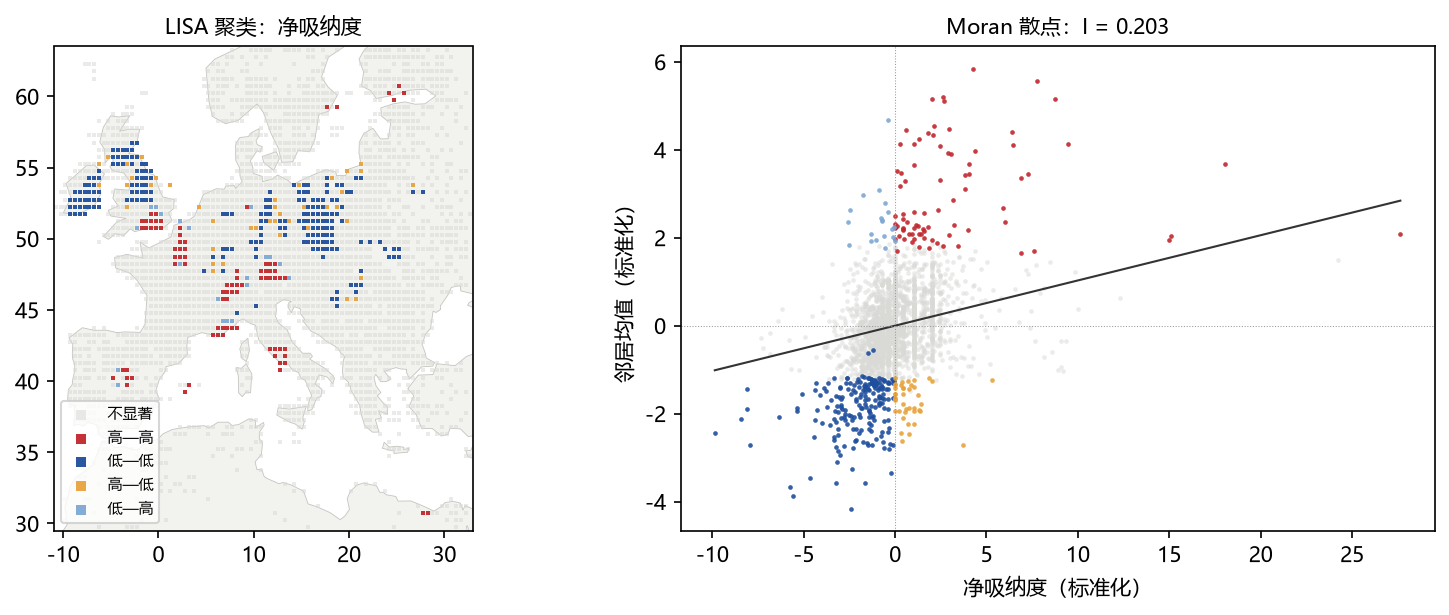

In [9]:
import json
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

plt.rcParams["font.family"] = ["Microsoft YaHei", "SimSun", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
COL = {"HH": "#C1272D", "LL": "#1F4E9C", "HL": "#E8A33D", "LH": "#7FA8D4", "ns": "#D9D9D6"}
LAB = {"HH": "高—高", "LL": "低—低", "HL": "高—低", "LH": "低—高", "ns": "不显著"}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi = 150,
                              gridspec_kw={"width_ratios": [1.15, 1]})

gj = json.load(open("ne_110m_land.geojson"))
polys = [np.array(p[0]) for f in gj["features"]
         for p in (f["geometry"]["coordinates"] if f["geometry"]["type"] == "MultiPolygon"
                   else [f["geometry"]["coordinates"]])]
ax.add_collection(PolyCollection(polys, facecolor="#F2F2EF", edgecolor="#C4C4BF", lw=0.4))
for key in ("ns", "HH", "LL", "HL", "LH"):
    m = (G.lisa_q == key).values
    ax.scatter(G.gx[m], G.gy[m], s=5, marker="s", c=COL[key], linewidths=0,
               alpha=0.55 if key == "ns" else 0.95, zorder=1 if key == "ns" else 2,
               label=LAB[key])
ax.set_xlim(-11, 33); ax.set_ylim(29.5, 63.5)
ax.set_aspect(1 / np.cos(np.radians(48)))
ax.set_title("LISA 聚类：净吸纳度", fontsize=10)
ax.legend(loc="lower left", fontsize=7, frameon=True, markerscale=2.2)

zc = G.z.values - G.z.values.mean()
lagv = zc[idx[:, 1:]].mean(axis=1)
I = float(zc @ lagv) / float(zc @ zc)
for key in ("ns", "HH", "LL", "HL", "LH"):
    m = (G.lisa_q == key).values
    ax2.scatter(zc[m], lagv[m], s=5, c=COL[key], linewidths=0,
                alpha=0.5 if key == "ns" else 0.9, zorder=1 if key == "ns" else 2)
xs = np.linspace(zc.min(), zc.max(), 10)
ax2.plot(xs, I * (lagv.std() / zc.std()) * xs, color="#333", lw=1)
ax2.axhline(0, color="#999", lw=0.5, ls=":"); ax2.axvline(0, color="#999", lw=0.5, ls=":")
ax2.set_xlabel("净吸纳度（标准化）"); ax2.set_ylabel("邻居均值（标准化）")
ax2.set_title(f"Moran 散点：I = {I:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
fig.savefig('fig7_3_spatial_notebook.pdf', bbox_inches = "tight", facecolor = "white")

## 5　回归：先诊断，再选模型

把"死亡数"对"出生数"回归，是在问：一个地方的死亡（即吸引来并留下的人）能在多大程度上
由它的出生规模解释？取对数后斜率接近 1 就意味着"出生与死亡大致等比"。

但如果残差本身有空间自相关，OLS 的标准误就是错的，系数也可能被遗漏的空间因素扭曲。
所以流程是：**先估计 OLS，再用拉格朗日乘数检验判断该加"滞后项"还是"误差项"。**

In [13]:
Y = np.log1p(G.D.values).reshape(-1, 1)
X = np.column_stack([np.ones(len(G)), np.log1p(G.B.values)])

ols = OLS(Y, X, w=w_pr, spat_diag=True, moran=True,
          name_y="log(死亡+1)", name_x=["常数", "log(出生+1)"])
print(f"β = {ols.betas[1,0]:.4f}（SE {ols.std_err[1]:.4f}），R² = {ols.r2:.4f}")
print(f"残差 Moran I = {ols.moran_res[0]:.4f}，z = {ols.moran_res[1]:.1f}"
      f"（p = {ols.moran_res[2]:.1e}）")
print()
for lab, a in [("LM-lag", "lm_lag"), ("LM-error", "lm_error"),
               ("稳健 LM-lag", "rlm_lag"), ("稳健 LM-error", "rlm_error")]:
    s, p = getattr(ols, a)
    print(f"{lab:>10}: {s:7.1f}   p = {p:.1e}")

β = 0.9245（SE 0.0111），R² = 0.7232
残差 Moran I = 0.2367，z = 25.3（p = 1.1e-140）

    LM-lag:   384.2   p = 1.5e-85
  LM-error:   631.5   p = 2.4e-139
 稳健 LM-lag:    72.7   p = 1.5e-17
稳健 LM-error:   320.0   p = 1.4e-71


四条统计量全部高度显著，说明"有空间依赖"这件事没有疑问。但方向要看**稳健形式**：
稳健 LM-error（320）远大于稳健 LM-lag（73）。

按 Anselin 的判别规则，这意味着残差里的空间结构来自**遗漏的区域变量**——
某些没进模型的因素（所在国的城市化水平、语言区、行政边界）在地理上相关，
它们被并进了误差项，而不是"邻居的死亡数直接影响了本地的死亡数"。

所以正确的规格是**空间误差模型**，不是空间滞后模型。这个判断如果跳过，
后面两个模型都能跑出显著结果，但解释会全错。

In [14]:
import contextlib, io

with contextlib.redirect_stdout(io.StringIO()):   # 屏蔽 spreg 构造时打印的模型名
    lag = ML_Lag(Y, X, w=w_pr, name_y="log(死亡+1)", name_x=["常数", "log(出生+1)"])
    err = ML_Error(Y, X, w=w_pr, name_y="log(死亡+1)", name_x=["常数", "log(出生+1)"])

rho = float(np.ravel(lag.rho)[0])
lam = float(np.ravel(err.lam)[0])
cmp = pd.DataFrame({
    "OLS":     [ols.betas[1,0], np.nan, ols.logll, ols.aic],
    "空间滞后": [lag.betas[1,0], rho, lag.logll, lag.aic],
    "空间误差": [err.betas[1,0], lam, err.logll, err.aic],
}, index=["β（log 出生）", "空间参数（ρ 或 λ）", "对数似然", "AIC"]).round(4)
cmp

C:\Users\Administrator\.workbuddy\binaries\python\pysal_pkgs\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


,OLS,空间滞后,空间误差
β（log 出生）,0.9245,0.7860,0.8602
空间参数（ρ 或 λ）,NaN,0.2895,0.5638
对数似然,-3078.4478,-2921.0351,-2875.0934
AIC,6160.8956,5848.0703,5754.1868


In [15]:
print(f"空间误差模型：λ = {lam:.4f}（SE {err.std_err[2]:.4f}，"
      f"z = {lam/err.std_err[2]:.1f}）")
print(f"空间滞后模型：ρ = {rho:.4f}（SE {lag.std_err[2]:.4f}，"
      f"z = {rho/lag.std_err[2]:.1f}）")
print(f"LR 检验（对 OLS）：误差 {2*(err.logll-ols.logll):.1f}，"
      f"滞后 {2*(lag.logll-ols.logll):.1f}（自由度均为 1）")
print(f"AIC：OLS {ols.aic:.0f} → 滞后 {lag.aic:.0f} → 误差 {err.aic:.0f}"
      f"（误差模型再省 {lag.aic-err.aic:.0f}）")

空间误差模型：λ = 0.5638（SE 0.0251，z = 22.5）
空间滞后模型：ρ = 0.2895（SE 0.0160，z = 18.1）
LR 检验（对 OLS）：误差 406.7，滞后 314.8（自由度均为 1）
AIC：OLS 6161 → 滞后 5848 → 误差 5754（误差模型再省 94）


**最后一步是检验残差。** 空间模型的意义就在于"把空间依赖吸收掉"，
所以要分别看四种残差：OLS 的残差、滞后模型的残差、误差模型的总残差 u，
以及误差模型的白噪声 ε = (I − λW)u。

In [16]:
Wm = w_pr.sparse.toarray()
eps = (np.eye(len(G)) - lam * Wm) @ err.u.flatten()

res = []
for lab, v in [("OLS 残差", ols.u.flatten()),
               ("滞后模型残差", (Y - lag.predy).flatten()),
               ("误差模型：总残差 u", err.u.flatten()),
               ("误差模型：白噪声 ε", eps)]:
    np.random.seed(42)
    m = Moran(v, w_pr, permutations=999)
    res.append({"残差": lab, "Moran I": round(m.I, 4), "p": m.p_sim})
pd.DataFrame(res)

,残差,Moran I,p
0,OLS 残差,0.2367,0.001
1,滞后模型残差,0.0901,0.001
2,误差模型：总残差 u,0.2586,0.001
3,误差模型：白噪声 ε,-0.0174,0.034


这是全篇最干净的一组数：**误差模型的白噪声 ε 的 I 降到 −0.017**，
空间依赖被吸收干净；而滞后模型只把 I 从 0.237 压到 0.090，仍高度显著。
AIC 与残差检验指向同一个结论——λ = 0.564 的误差模型才是对的。

λ 怎么读：一个城市"未被观测的区域因素"中，约 56% 来自邻居。
反过来说，只要模型里没有纳入国别、语言区、城市化阶段这类区域变量，
残差就一定会成片——这正是空间误差模型要处理的东西。

**附带一个反例，说明选错设定的代价。** 如果坚持用滞后模型，
系数会被空间乘子放大，解释就会失真：

In [17]:
S = np.linalg.inv(np.eye(len(G)) - rho * Wm)
b1 = float(lag.betas[1, 0])
direct = float(np.trace(S) / len(G) * b1)
total = float(S.sum() / len(G) * b1)
print(f"滞后模型的影响分解：直接 {direct:.3f}，间接（邻居溢出）{total-direct:.3f}，"
      f"总效应 {total:.3f}")
print(f"（β/(1−ρ) 的放大：{b1:.3f} × 1/(1−{rho:.3f}) = {b1/(1-rho):.3f}）")
print(f"误差模型不含全局溢出，效应就是 β = {float(err.betas[1,0]):.3f}")

滞后模型的影响分解：直接 0.795，间接（邻居溢出）0.312，总效应 1.106
（β/(1−ρ) 的放大：0.786 × 1/(1−0.289) = 1.106）
误差模型不含全局溢出，效应就是 β = 0.860


## 6　结论

**实质发现**

1. **规模聚集，净吸纳只是弱聚集。** 出生数与死亡数的 Moran's I 都在 0.47—0.48，
   净吸纳度只有 0.20。"哪里人多"是强空间过程，"哪里留得住人"要弱得多。
2. **聚集是成片的，且分成两类区域。** 高—高 83 个单元，是伦敦、巴黎、慕尼黑、罗马
   一带的首都圈；低—低 197 个，是爱尔兰、苏格兰、英格兰北部与威尔士。
   磁铁与输出地各自连片，中间只有 61 个过渡单元。
3. **出生规模解释了七成方差，但解释不干净。** OLS 的 β = 0.924、R² = 0.723，
   残差 I = 0.237。加了空间误差项后 λ = 0.564，白噪声残差的 I 降到 −0.017，
   AIC 从 6161 降到 5754。

**方法论上要交代的五件事**

| 项 | 本例取值 | 为什么必须报 |
|---|---|---|
| 空间单元 | 0.5° 格网，2,670 个 | 换尺度 I 会从 0.28 变到 0.57（MAUP） |
| 距离与投影 | LAEA（EPSG:3035）kNN，k=8 | 不投影会换掉约 9% 的邻居 |
| 权重标准化 | 行标准化 | 否则 ρ 的量纲差 k 倍 |
| 置换次数与种子 | 999 次，seed=42 | 显著名单在边界带会摆动 |
| 模型选择依据 | 稳健 LM-error ≫ 稳健 LM-lag | 选错设定，系数解释会整体失真 |

空间回归与普通回归真正不同的地方，不是多加了一个 ρ 或 λ，而是**多了一道诊断工序**：
先用 OLS 把空间依赖找出来，再决定让它进均值方程（滞后）还是进误差项（误差）。
诊断只花一次矩阵运算，却能决定整段解释的方向。